# Online Retail Sales Analysis

**Tools:** Python (Pandas, NumPy), SQL (SQLite), Matplotlib, Seaborn, Plotly

**Dataset:** UCI Online Retail dataset (541,909 rows, 8 columns). It has every sale made by a UK-based online gift shop between 1 Dec 2010 and 9 Dec 2011. Amounts are shown in pounds because the shop is in the UK (the file itself does not name the currency).

**What I want to find out**
1. How did sales change month by month, and when is the shop busiest?
2. Which products and countries bring in the most money?
3. How much money is lost to cancellations and returns?
4. Who are the best customers, and how much of the revenue depends on a small group of them?

**How the notebook is organised**
1. Load the data and look at it
2. Check data quality with SQL
3. Clean the data (every step is logged)
4. Answer business questions with SQL
5. Customer analysis with Python (RFM scores, RF-based segments)
6. Charts, including scatter plots
7. Findings
8. Save the cleaned files

In [1]:
import os, json
import numpy as np
import pandas as pd
import sqlite3
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from scipy.stats import spearmanr

pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

os.makedirs("charts", exist_ok=True)
os.makedirs("outputs", exist_ok=True)

## 1. Load the data

The file is not UTF-8, so I read it with `latin-1`. Dates are written day first (`01-12-2010` is 1 December 2010), so I tell Pandas to read them that way. If I skipped this, 1 December would be read as 12 January and every month would be wrong.

In [2]:
DATA_PATH = "OnlineRetail.csv"   # download link is in the README

raw = pd.read_csv(DATA_PATH, encoding="latin-1")
raw["InvoiceDate"] = pd.to_datetime(raw["InvoiceDate"], dayfirst=True)
raw["InvoiceNo"] = raw["InvoiceNo"].astype(str)
raw["StockCode"] = raw["StockCode"].astype(str)

print("Rows and columns:", raw.shape)
print("Date range:", raw["InvoiceDate"].min(), "to", raw["InvoiceDate"].max())
raw.head()

Rows and columns: (541909, 8)
Date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,"17,850.00",United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,"17,850.00",United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom


In [3]:
raw.describe(include='all').T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,541909,25900,573585,1114,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,"541,909.00",NaN,NaN,NaN,9.55,"-80,995.00",1.00,3.00,10.00,"80,995.00",218.08
InvoiceDate,541909,NaN,NaN,NaN,2011-07-04 13:34:57.156386,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,"541,909.00",NaN,NaN,NaN,4.61,"-11,062.06",1.25,2.08,4.13,"38,970.00",96.76
CustomerID,"406,829.00",NaN,NaN,NaN,"15,287.69","12,346.00","13,953.00","15,152.00","16,791.00","18,287.00","1,713.60"
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


What I notice at first look:
- `Quantity` and `UnitPrice` have negative or zero values, which should not happen in a normal sale.
- `CustomerID` is missing for a large part of the rows.
- The date range stops on 9 December 2011, so December 2011 is only a partial month.

## 2. Check data quality with SQL

I load the raw data into a SQLite table and write SQL to count the problems before I change anything.

In [4]:
con = sqlite3.connect(":memory:")

raw_sql = raw.copy()
raw_sql["InvoiceDate"] = raw_sql["InvoiceDate"].dt.strftime("%Y-%m-%d %H:%M:%S")
raw_sql.to_sql("raw_sales", con, index=False)

def q(sql):
    return pd.read_sql_query(sql, con)

In [5]:
q('''
SELECT COUNT(*)                         AS total_rows,
       SUM(CustomerID IS NULL)          AS missing_customer_id,
       SUM(Description IS NULL)         AS missing_description,
       SUM(Quantity <= 0)               AS qty_zero_or_negative,
       SUM(UnitPrice <= 0)              AS price_zero_or_negative,
       SUM(InvoiceNo LIKE 'C%')         AS cancelled_lines
FROM raw_sales
''')

,total_rows,missing_customer_id,missing_description,qty_zero_or_negative,price_zero_or_negative,cancelled_lines
0,541909,135080,1454,10624,2517,9288


In [6]:
# Exact duplicate rows: same values in every column
q('''
SELECT SUM(cnt - 1) AS extra_duplicate_rows
FROM (
    SELECT COUNT(*) AS cnt
    FROM raw_sales
    GROUP BY InvoiceNo, StockCode, Description, Quantity, InvoiceDate, UnitPrice, CustomerID, Country
    HAVING COUNT(*) > 1
)
''')

,extra_duplicate_rows
0,5268


In [7]:
# Stock codes that are not products (they do not start with a 5 digit product number)
q('''
SELECT StockCode, MAX(Description) AS description, COUNT(*) AS rows_count, ROUND(SUM(Quantity * UnitPrice), 0) AS value
FROM raw_sales
WHERE StockCode NOT GLOB '[0-9][0-9][0-9][0-9][0-9]*'
GROUP BY StockCode
ORDER BY rows_count DESC
LIMIT 10
''')

,StockCode,description,rows_count,value
0,POST,POSTAGE,1256,"66,231.00"
1,DOT,DOTCOM POSTAGE,710,"206,245.00"
2,M,Manual,571,"-68,674.00"
3,C2,CARRIAGE,144,"6,986.00"
4,D,Discount,77,"-5,696.00"
5,S,SAMPLES,63,"-3,049.00"
6,BANK CHARGES,Bank Charges,37,"-7,176.00"
7,AMAZONFEE,AMAZON FEE,34,"-221,521.00"
8,CRUK,CRUK Commission,16,"-7,933.00"
9,DCGSSGIRL,GIRLS PARTY BAG,13,144.00


The non-product codes are things like postage (`POST`), bank charges, Amazon fees, manual adjustments and gift vouchers. They are real money movements, but they are not product sales, so they would distort a product analysis.

In [8]:
# The biggest single order lines. Two of them look suspicious.
q('''
SELECT InvoiceNo, StockCode, Description, Quantity, UnitPrice, InvoiceDate, CustomerID
FROM raw_sales
ORDER BY Quantity DESC
LIMIT 3
''')

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,InvoiceDate,CustomerID
0,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,2011-12-09 09:15:00,"16,446.00"
1,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,2011-01-18 10:01:00,"12,346.00"
2,578841,84826,ASSTD DESIGN 3D PAPER STICKERS,12540,0.00,2011-11-25 15:57:00,"13,256.00"


In [9]:
# Look for a cancellation of those two huge orders
q('''
SELECT InvoiceNo, Description, Quantity, UnitPrice, InvoiceDate, CustomerID
FROM raw_sales
WHERE InvoiceNo IN ('581483', 'C581484', '541431', 'C541433')
ORDER BY StockCode, InvoiceDate
''')

,InvoiceNo,Description,Quantity,UnitPrice,InvoiceDate,CustomerID
0,541431,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,2011-01-18 10:01:00,"12,346.00"
1,C541433,MEDIUM CERAMIC TOP STORAGE JAR,-74215,1.04,2011-01-18 10:17:00,"12,346.00"
2,581483,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,2011-12-09 09:15:00,"16,446.00"
3,C581484,"PAPER CRAFT , LITTLE BIRDIE",-80995,2.08,2011-12-09 09:27:00,"16,446.00"


Both huge orders (80,995 and 74,215 units) were cancelled within about 15 minutes, with the same item, quantity and price. They are not real demand, so I will remove the order and its cancellation. If I keep them, they would add roughly £245,000 of fake revenue.

## 3. Clean the data

Every step is written to a log with the number of rows before and after, so each decision can be checked.

My decisions:
- **Duplicates:** remove exact duplicates.
- **Cancellations:** invoices starting with `C` are cancellations. I do not delete them. I move them into a separate `returns` table so I can study returns, and I keep them out of the sales numbers.
- **Non-product codes:** remove from sales and returns.
- **Zero or negative quantity or price:** remove from sales (stock adjustments, damaged goods notes, free items).
- **The two cancelled huge orders:** remove with their cancellations.
- **Missing `CustomerID`:** I keep these rows for sales, product and country analysis, because they are real sales. I leave them out only for customer analysis, since I cannot link them to a person.

In [10]:
log = []
def step(name, before, after):
    log.append({"step": name, "rows_before": before, "rows_after": after, "rows_removed": before - after})

df = raw.copy()

# 1. exact duplicates
n = len(df)
df = df.drop_duplicates()
step("Remove exact duplicate rows", n, len(df))

# 2. cancellations go to a separate table
is_cancel = df["InvoiceNo"].str.startswith("C")
returns = df[is_cancel].copy()
n = len(df)
df = df[~is_cancel]
step("Move cancellations (invoice starts with C) to the returns table", n, len(df))

# 3. non-product stock codes
is_product = df["StockCode"].str.match(r"^\d{5}")
n = len(df)
df = df[is_product]
step("Remove non-product codes (postage, fees, vouchers, adjustments)", n, len(df))
returns = returns[returns["StockCode"].str.match(r"^\d{5}")]

# 4. zero or negative quantity / price
n = len(df)
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]
step("Remove rows with zero or negative quantity or price", n, len(df))

# 5. the two huge orders that were cancelled within minutes
n = len(df)
df = df[df["Quantity"] < 10000]
step("Remove 2 huge orders that were cancelled within minutes", n, len(df))
returns = returns[returns["Quantity"].abs() < 10000]

pd.DataFrame(log)

,step,rows_before,rows_after,rows_removed
0,Remove exact duplicate rows,541909,536641,5268
1,Move cancellations (invoice starts with C) to ...,536641,527390,9251
2,"Remove non-product codes (postage, fees, vouch...",527390,524984,2406
3,Remove rows with zero or negative quantity or ...,524984,522504,2480
4,Remove 2 huge orders that were cancelled withi...,522504,522502,2


In [11]:
# Tidy up the remaining columns
df["Description"] = df["Description"].str.strip()
returns["Description"] = returns["Description"].str.strip()
df["CustomerID"] = df["CustomerID"].astype("Int64")
returns["CustomerID"] = returns["CustomerID"].astype("Int64")

# New columns
for d in (df, returns):
    d["Revenue"] = d["Quantity"] * d["UnitPrice"]
    d["Month"] = d["InvoiceDate"].dt.strftime("%Y-%m")
    d["Weekday"] = d["InvoiceDate"].dt.day_name()
    d["Hour"] = d["InvoiceDate"].dt.hour

print("Clean sales rows:", len(df))
print("Returns rows:", len(returns))
print("Missing Description in clean sales:", df["Description"].isna().sum())
print("Missing CustomerID in clean sales:", df["CustomerID"].isna().sum(),
      f"({df['CustomerID'].isna().mean():.1%} of rows)")
print(f"Revenue from rows with no CustomerID: {df.loc[df['CustomerID'].isna(), 'Revenue'].sum() / df['Revenue'].sum():.1%}")
df.head()

Clean sales rows: 522502
Returns rows: 8666
Missing Description in clean sales: 0
Missing CustomerID in clean sales: 131354 (25.1% of rows)
Revenue from rows with no CustomerID: 15.1%


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,Month,Weekday,Hour
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30,2010-12,Wednesday,8
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12,Wednesday,8
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00,2010-12,Wednesday,8
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12,Wednesday,8
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12,Wednesday,8


Next I load the clean tables into SQLite so I can answer the business questions with SQL.

In [12]:
def to_sql_table(d, name):
    t = d.rename(columns={
        "InvoiceNo": "invoice_no", "StockCode": "stock_code", "Description": "description",
        "Quantity": "quantity", "InvoiceDate": "invoice_date", "UnitPrice": "unit_price",
        "CustomerID": "customer_id", "Country": "country", "Revenue": "revenue",
        "Month": "month", "Weekday": "weekday", "Hour": "hour"}).copy()
    t["invoice_date"] = t["invoice_date"].dt.strftime("%Y-%m-%d %H:%M:%S")
    t.to_sql(name, con, index=False, if_exists="replace")

to_sql_table(df, "sales")
to_sql_table(returns, "returns")
q("SELECT COUNT(*) AS sales_rows FROM sales")

,sales_rows
0,522502


## 4. Business questions answered with SQL

### Q1. How do monthly sales change?
This uses a window function (`LAG`) to compare each month with the one before.

In [13]:
monthly_sql = q('''
WITH monthly AS (
    SELECT month,
           ROUND(SUM(revenue), 0)                                AS revenue,
           COUNT(DISTINCT invoice_no)                            AS orders,
           ROUND(SUM(revenue) / COUNT(DISTINCT invoice_no), 2)   AS avg_order_value
    FROM sales
    GROUP BY month
)
SELECT month, revenue, orders, avg_order_value,
       ROUND(100.0 * (revenue - LAG(revenue) OVER (ORDER BY month))
             / LAG(revenue) OVER (ORDER BY month), 1)            AS pct_change_vs_prev_month
FROM monthly
ORDER BY month
''')
monthly_sql

,month,revenue,orders,avg_order_value,pct_change_vs_prev_month
0,2010-12,"775,572.00",1550,500.37,NaN
1,2011-01,"593,178.00",1080,549.24,-23.50
2,2011-02,"507,783.00",1093,464.58,-14.40
3,2011-03,"689,708.00",1440,478.96,35.80
4,2011-04,"515,355.00",1235,417.29,-25.30
5,2011-05,"739,914.00",1668,443.59,43.60
6,2011-06,"737,559.00",1525,483.65,-0.30
7,2011-07,"688,145.00",1452,473.93,-6.70
8,2011-08,"724,197.00",1339,540.85,5.20
9,2011-09,"1,028,314.00",1818,565.63,42.00


December 2011 looks like a big drop, but the data stops on 9 December, so that month has only a few days. I compare it fairly in the next cell.

In [14]:
days = df.groupby("Month")["InvoiceDate"].apply(lambda s: s.dt.date.nunique()).rename("trading_days")
per_day = (df.groupby("Month")["Revenue"].sum() / days).rename("revenue_per_trading_day")
pd.concat([days, per_day], axis=1).tail(4)

,trading_days,revenue_per_trading_day
Month,,
2011-09,26,"39,550.53"
2011-10,26,"42,435.04"
2011-11,26,"55,850.49"
2011-12,8,"55,752.25"


### Q2. Which products bring in the most money?

In [15]:
q('''
SELECT stock_code,
       MAX(description)                       AS product,
       SUM(quantity)                          AS units_sold,
       ROUND(SUM(revenue), 0)                 AS revenue,
       ROUND(100.0 * SUM(revenue) / (SELECT SUM(revenue) FROM sales), 2) AS pct_of_total_revenue
FROM sales
GROUP BY stock_code
ORDER BY revenue DESC
LIMIT 10
''')

,stock_code,product,units_sold,revenue,pct_of_total_revenue
0,22423,REGENCY CAKESTAND 3 TIER,13851,"174,157.00",1.74
1,85123A,WHITE HANGING HEART T-LIGHT HOLDER,37641,"104,463.00",1.04
2,47566,PARTY BUNTING,18283,"99,445.00",0.99
3,85099B,JUMBO BAG RED RETROSPOT,48371,"94,160.00",0.94
4,23084,RABBIT NIGHT LIGHT,30739,"66,870.00",0.67
5,22086,PAPER CHAIN KIT 50'S CHRISTMAS,19329,"64,876.00",0.65
6,84879,ASSORTED COLOUR BIRD ORNAMENT,36362,"58,928.00",0.59
7,79321,CHILLI LIGHTS,10302,"54,096.00",0.54
8,22502,PICNIC BASKET WICKER SMALL,1937,"51,409.00",0.51
9,22197,SMALL POPCORN HOLDER,56898,"51,334.00",0.51


### Q3. Which countries bring in the most money?

In [16]:
q('''
SELECT country,
       COUNT(DISTINCT invoice_no)   AS orders,
       COUNT(DISTINCT customer_id)  AS customers,
       ROUND(SUM(revenue), 0)       AS revenue,
       ROUND(100.0 * SUM(revenue) / SUM(SUM(revenue)) OVER (), 2) AS pct_of_total
FROM sales
GROUP BY country
ORDER BY revenue DESC
LIMIT 10
''')

,country,orders,customers,revenue,pct_of_total
0,United Kingdom,17899,3915,"8,478,392.00",84.77
1,Netherlands,93,9,"283,889.00",2.84
2,EIRE,282,3,"270,851.00",2.71
3,Germany,443,94,"205,381.00",2.05
4,France,382,87,"184,493.00",1.84
5,Australia,56,9,"138,104.00",1.38
6,Spain,88,30,"55,707.00",0.56
7,Switzerland,50,21,"53,066.00",0.53
8,Japan,19,8,"37,416.00",0.37
9,Belgium,98,25,"36,927.00",0.37


### Q4. What is the best-selling product in each of the top 5 countries?
This uses `RANK()` with `PARTITION BY`.

In [17]:
q('''
WITH p AS (
    SELECT country, stock_code, MAX(description) AS product, ROUND(SUM(revenue), 0) AS revenue,
           RANK() OVER (PARTITION BY country ORDER BY SUM(revenue) DESC) AS rk
    FROM sales
    WHERE country IN (SELECT country FROM sales GROUP BY country ORDER BY SUM(revenue) DESC LIMIT 5)
    GROUP BY country, stock_code
)
SELECT country, product, revenue
FROM p
WHERE rk = 1
ORDER BY revenue DESC
''')

,country,product,revenue
0,United Kingdom,REGENCY CAKESTAND 3 TIER,"141,996.00"
1,Netherlands,RABBIT NIGHT LIGHT,"9,568.00"
2,Germany,REGENCY CAKESTAND 3 TIER,"9,062.00"
3,EIRE,REGENCY CAKESTAND 3 TIER,"7,793.00"
4,France,RABBIT NIGHT LIGHT,"7,277.00"


### Q5. Which days and hours are the busiest?

In [18]:
q('''
SELECT weekday, COUNT(DISTINCT invoice_no) AS orders, ROUND(SUM(revenue), 0) AS revenue
FROM sales
GROUP BY weekday
ORDER BY revenue DESC
''')

,weekday,orders,revenue
0,Thursday,4209,"2,131,558.00"
1,Tuesday,3508,"2,007,733.00"
2,Wednesday,3667,"1,782,236.00"
3,Monday,3076,"1,682,764.00"
4,Friday,3108,"1,598,564.00"
5,Sunday,2203,"798,312.00"


In [19]:
q('''
SELECT hour, COUNT(DISTINCT invoice_no) AS orders, ROUND(SUM(revenue), 0) AS revenue
FROM sales
GROUP BY hour
ORDER BY orders DESC
LIMIT 5
''')

,hour,orders,revenue
0,12,3205,"1,412,918.00"
1,13,2730,"1,220,334.00"
2,14,2419,"1,119,611.00"
3,11,2373,"1,196,788.00"
4,10,2338,"1,324,540.00"


### Q6. How many customers come back?

In [20]:
q('''
WITH c AS (
    SELECT customer_id, COUNT(DISTINCT invoice_no) AS orders, SUM(revenue) AS revenue
    FROM sales
    WHERE customer_id IS NOT NULL
    GROUP BY customer_id
)
SELECT CASE WHEN orders = 1 THEN '1 order'
            WHEN orders BETWEEN 2 AND 5 THEN '2 to 5 orders'
            ELSE '6 or more orders' END   AS customer_group,
       COUNT(*)                           AS customers,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS pct_of_customers,
       ROUND(SUM(revenue), 0)             AS revenue,
       ROUND(100.0 * SUM(revenue) / SUM(SUM(revenue)) OVER (), 1) AS pct_of_revenue
FROM c
GROUP BY customer_group
ORDER BY MIN(orders)
''')

,customer_group,customers,pct_of_customers,revenue,pct_of_revenue
0,1 order,1505,34.70,"549,425.00",6.50
1,2 to 5 orders,1963,45.30,"2,165,503.00",25.50
2,6 or more orders,865,20.00,"5,776,646.00",68.00


### Q7. Who are the top 10 customers, and how much of the revenue do they cover together?
The running total uses a window function.

In [21]:
q('''
WITH cust AS (
    SELECT customer_id, COUNT(DISTINCT invoice_no) AS orders, ROUND(SUM(revenue), 0) AS revenue
    FROM sales
    WHERE customer_id IS NOT NULL
    GROUP BY customer_id
)
SELECT customer_id, orders, revenue,
       ROUND(100.0 * SUM(revenue) OVER (ORDER BY revenue DESC)
             / (SELECT SUM(revenue) FROM sales WHERE customer_id IS NOT NULL), 1) AS cumulative_pct_of_known_revenue
FROM cust
ORDER BY revenue DESC
LIMIT 10
''')

,customer_id,orders,revenue,cumulative_pct_of_known_revenue
0,14646,72,"279,138.00",3.30
1,18102,60,"259,657.00",6.30
2,17450,46,"194,391.00",8.60
3,14911,198,"136,162.00",10.20
4,12415,20,"124,565.00",11.70
5,14156,54,"116,560.00",13.10
6,17511,31,"91,062.00",14.10
7,16029,62,"72,708.00",15.00
8,16684,28,"66,654.00",15.80
9,13694,50,"65,040.00",16.60


### Q8. How much money goes back through returns?

In [22]:
q('''
SELECT 'sales' AS table_name, COUNT(DISTINCT invoice_no) AS invoices, ROUND(SUM(revenue), 0) AS value FROM sales
UNION ALL
SELECT 'returns', COUNT(DISTINCT invoice_no), ROUND(SUM(revenue), 0) FROM returns
''')

,table_name,invoices,value
0,sales,19771,"10,001,168.00"
1,returns,3420,"-230,248.00"


In [23]:
q('''
SELECT stock_code, MAX(description) AS product,
       SUM(-quantity) AS units_returned, ROUND(SUM(-revenue), 0) AS value_returned
FROM returns
GROUP BY stock_code
ORDER BY value_returned DESC
LIMIT 10
''')

,stock_code,product,units_returned,value_returned
0,22423,REGENCY CAKESTAND 3 TIER,855,"9,697.00"
1,85123A,WHITE HANGING HEART T-LIGHT HOLDER,2578,"6,624.00"
2,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3150,"6,591.00"
3,23113,PANTRY CHOPPING BOARD,946,"4,803.00"
4,48185,DOORMAT FAIRY CAKE,674,"4,555.00"
5,21175,GIN + TONIC DIET METAL SIGN,2030,"3,775.00"
6,47566B,TEA TIME PARTY BUNTING,1424,"3,693.00"
7,22273,FELTCRAFT DOLL MOLLY,1447,"3,513.00"
8,71477,COLOURED GLASS STAR T-LIGHT HOLDER,1228,"3,444.00"
9,22191,IVORY DINER WALL CLOCK,344,"2,654.00"


## 5. Customer analysis in Python (RFM)

RFM scores every customer on three things:
- **Recency:** how many days since the last purchase (fewer is better)
- **Frequency:** how many separate orders
- **Monetary:** how much money they spent

Each one gets a score from 1 to 5, using cut points taken from the 20th, 40th, 60th and 80th percentile of the data. Only rows with a `CustomerID` are used.

I use the percentile cut points directly instead of `qcut`. Many customers have exactly one order, and `qcut` would split these equal customers into different groups at random.

**How segments are assigned:** the segment rules use only R and F. M is scored too, but it is not used in the rules; it is reported as spend per segment instead. I did this because frequency and spend move together in this data (Spearman correlation 0.81, from `outputs/rfm_customers.csv`), and Champions spend about £5,542 on average against £448 for Lost customers. So this is an RF-based segmentation with spend reported, not a three-way RFM rule set.

In [24]:
cust = df.dropna(subset=["CustomerID"]).copy()
snapshot = cust["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)   # the day after the last sale

rfm = cust.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda s: (snapshot - s.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("Revenue", "sum"),
).reset_index()

def score(series, higher_is_better=True):
    cuts = series.quantile([0.2, 0.4, 0.6, 0.8]).values
    s = np.digitize(series, cuts, right=True) + 1
    return s if higher_is_better else 6 - s

rfm["R"] = score(rfm["Recency"], higher_is_better=False)
rfm["F"] = score(rfm["Frequency"])
rfm["M"] = score(rfm["Monetary"])

# Segment rules use R and F only. M is scored but only used to report spend per segment.
def segment(row):
    R, F = row["R"], row["F"]
    if R >= 4 and F >= 4: return "Champions"
    if R >= 3 and F >= 3: return "Loyal Customers"
    if R >= 4 and F <= 2: return "New / Recent Customers"
    if R <= 2 and F >= 3: return "At Risk"
    if R <= 2 and F <= 2: return "Lost"
    return "Need Attention"

rfm["Segment"] = rfm.apply(segment, axis=1)
rfm.head()

,CustomerID,Recency,Frequency,Monetary,R,F,M,Segment
0,12347,2,7,"4,310.00",5,5,5,Champions
1,12348,75,4,"1,437.24",2,4,4,At Risk
2,12349,18,1,"1,457.55",4,1,4,New / Recent Customers
3,12350,310,1,294.40,1,1,2,Lost
4,12352,36,7,"1,385.74",3,5,4,Loyal Customers


In [25]:
seg = rfm.groupby("Segment").agg(
    customers=("CustomerID", "count"),
    revenue=("Monetary", "sum"),
    avg_orders=("Frequency", "mean"),
    avg_days_since_last_order=("Recency", "mean"),
).reset_index()
seg["pct_of_customers"] = 100 * seg["customers"] / seg["customers"].sum()
seg["pct_of_revenue"] = 100 * seg["revenue"] / seg["revenue"].sum()
seg = seg.sort_values("revenue", ascending=False).reset_index(drop=True)
seg

,Segment,customers,revenue,avg_orders,avg_days_since_last_order,pct_of_customers,pct_of_revenue
0,Champions,1023,"5,669,319.03",10.67,12.13,23.61,66.76
1,Loyal Customers,591,"1,082,376.87",4.47,38.13,13.64,12.75
2,At Risk,384,"638,035.26",4.35,135.03,8.86,7.51
3,Lost,1340,"600,858.12",1.28,208.35,30.93,7.08
4,New / Recent Customers,517,"252,168.14",1.54,16.84,11.93,2.97
5,Need Attention,478,"248,817.02",1.37,52.10,11.03,2.93


### How much revenue depends on a small group of customers?

In [26]:
r = rfm.sort_values("Monetary", ascending=False).reset_index(drop=True)
r["cum_revenue_pct"] = 100 * r["Monetary"].cumsum() / r["Monetary"].sum()
r["cum_customers_pct"] = 100 * (r.index + 1) / len(r)

top20_share = r.loc[r["cum_customers_pct"] <= 20, "cum_revenue_pct"].iloc[-1]
cust_for_80 = r.loc[r["cum_revenue_pct"] >= 80, "cum_customers_pct"].iloc[0]
print(f"Top 20% of customers bring {top20_share:.1f}% of the revenue from known customers")
print(f"80% of that revenue comes from the top {cust_for_80:.1f}% of customers")

Top 20% of customers bring 73.9% of the revenue from known customers
80% of that revenue comes from the top 26.8% of customers


## 6. Charts

### Monthly revenue

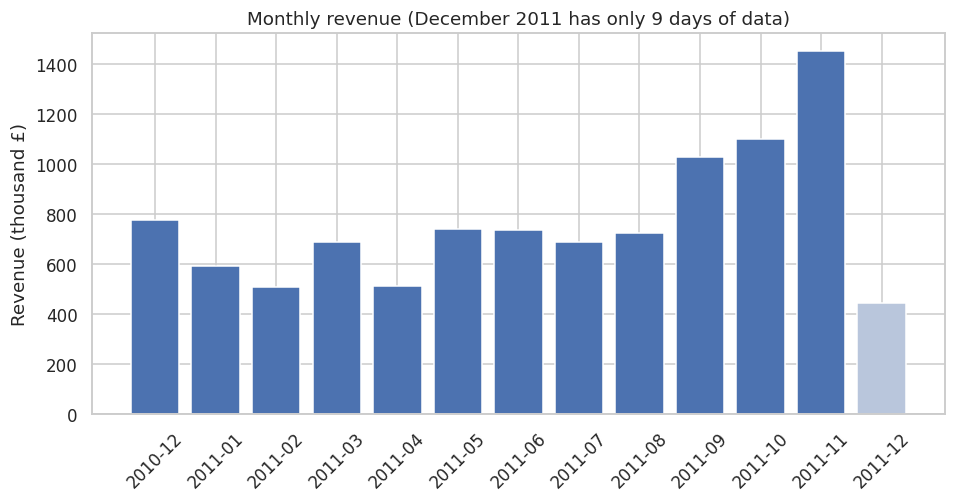

In [27]:
monthly = df.groupby("Month")["Revenue"].sum().reset_index()
fig, ax = plt.subplots(figsize=(10, 4.5))
colors = ["#4C72B0"] * (len(monthly) - 1) + ["#B9C6DC"]
ax.bar(monthly["Month"], monthly["Revenue"] / 1000, color=colors)
ax.set_title("Monthly revenue (December 2011 has only 9 days of data)")
ax.set_ylabel("Revenue (thousand £)")
ax.set_xlabel("")
plt.xticks(rotation=45)
plt.savefig("charts/01_monthly_revenue.png", bbox_inches="tight")
plt.show()

### Top 10 products by revenue

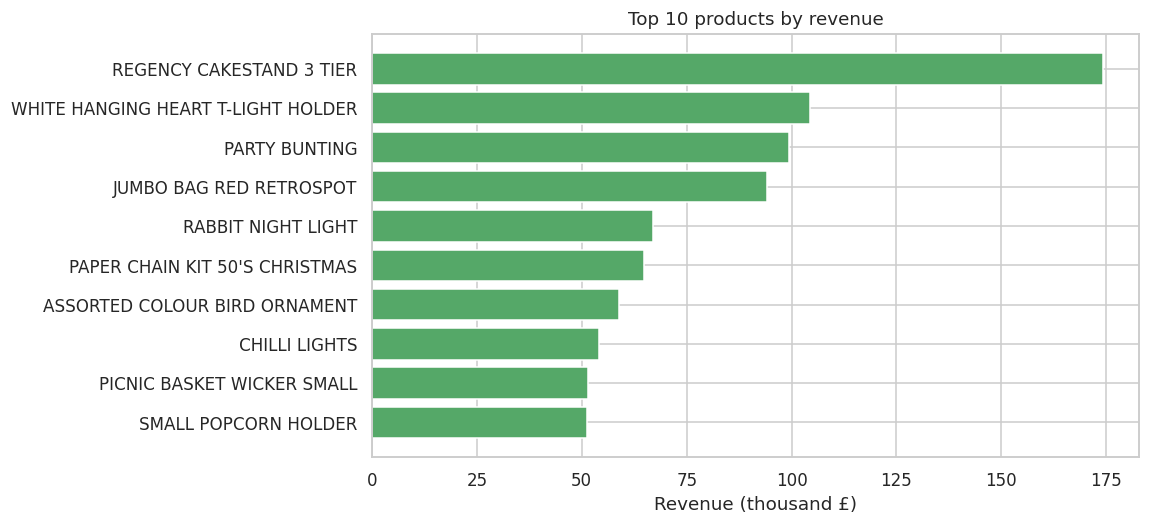

In [28]:
top_products = (df.groupby(["StockCode"]).agg(product=("Description", "first"), revenue=("Revenue", "sum"))
                .sort_values("revenue", ascending=False).head(10).iloc[::-1])
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(top_products["product"], top_products["revenue"] / 1000, color="#55A868")
ax.set_title("Top 10 products by revenue")
ax.set_xlabel("Revenue (thousand £)")
plt.savefig("charts/02_top_products.png", bbox_inches="tight")
plt.show()

### Revenue by country (without the UK)

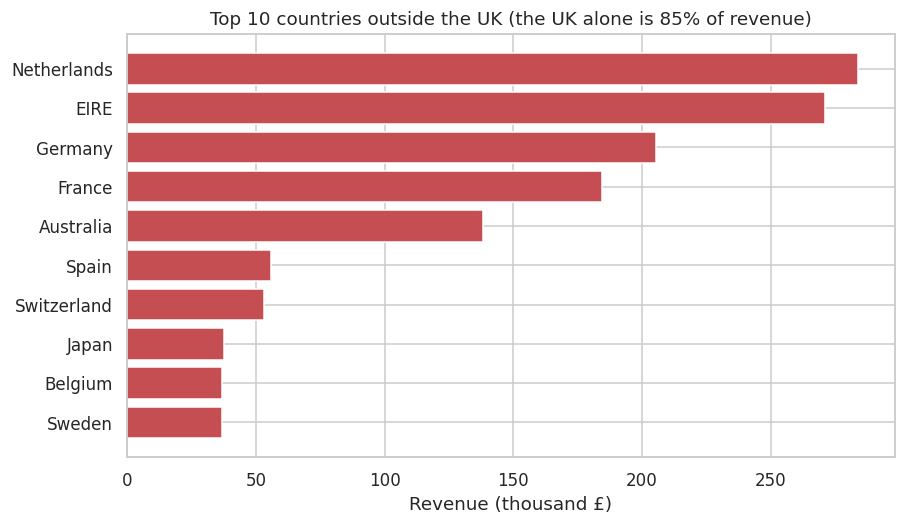

In [29]:
country = df.groupby("Country").agg(revenue=("Revenue", "sum"), orders=("InvoiceNo", "nunique")).reset_index()
uk_share = country.loc[country["Country"] == "United Kingdom", "revenue"].sum() / country["revenue"].sum()
other = country[country["Country"] != "United Kingdom"].sort_values("revenue", ascending=False).head(10).iloc[::-1]

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(other["Country"], other["revenue"] / 1000, color="#C44E52")
ax.set_title(f"Top 10 countries outside the UK (the UK alone is {uk_share:.0%} of revenue)")
ax.set_xlabel("Revenue (thousand £)")
plt.savefig("charts/03_country_revenue.png", bbox_inches="tight")
plt.show()

### When do customers order? (number of orders by weekday and hour)

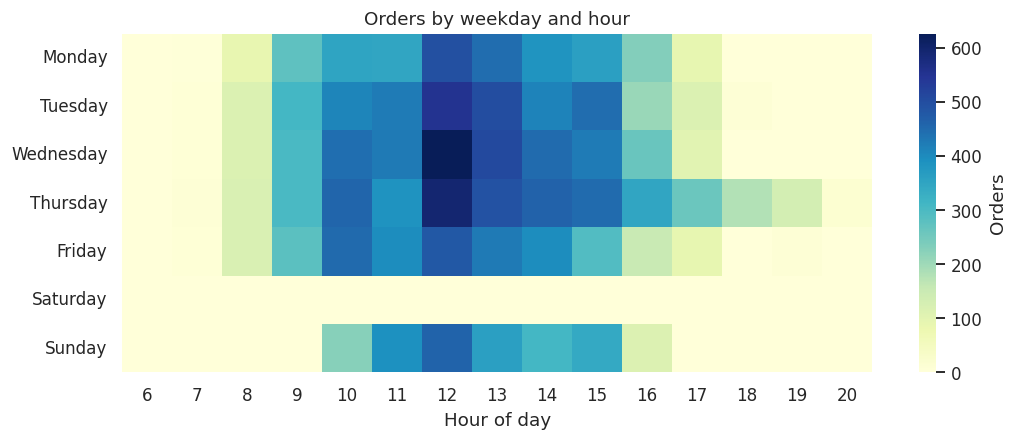

Days with orders: ['Friday', 'Monday', 'Sunday', 'Thursday', 'Tuesday', 'Wednesday']


In [30]:
order_days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
heat = (df.groupby(["Weekday", "Hour"])["InvoiceNo"].nunique().unstack(fill_value=0)
          .reindex(order_days).fillna(0))
fig, ax = plt.subplots(figsize=(11, 4))
sns.heatmap(heat, cmap="YlGnBu", ax=ax, cbar_kws={"label": "Orders"})
ax.set_title("Orders by weekday and hour")
ax.set_xlabel("Hour of day")
ax.set_ylabel("")
plt.savefig("charts/04_orders_weekday_hour.png", bbox_inches="tight")
plt.show()
print("Days with orders:", sorted(df["Weekday"].unique()))

### Customer segments: share of customers vs share of revenue

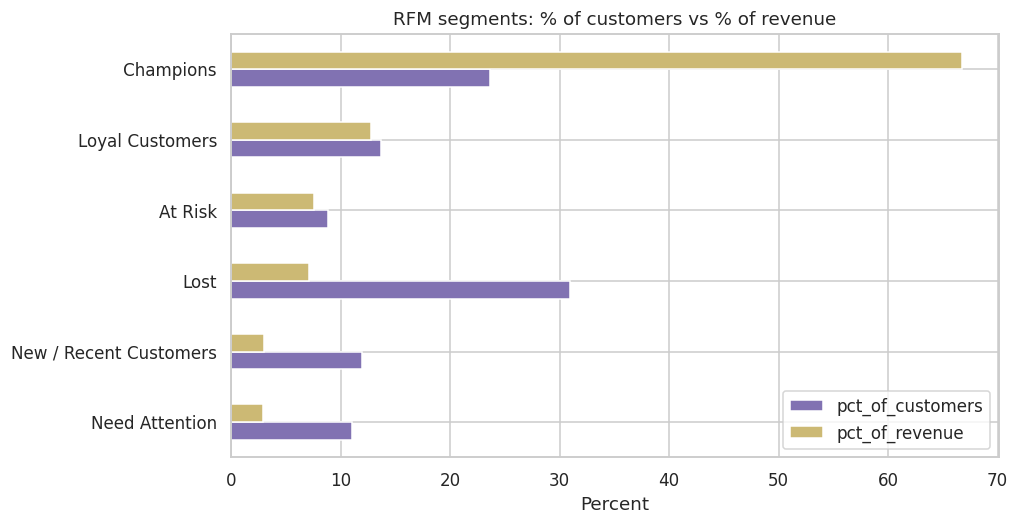

In [31]:
seg_plot = seg.set_index("Segment")[["pct_of_customers", "pct_of_revenue"]].sort_values("pct_of_revenue")
ax = seg_plot.plot(kind="barh", figsize=(9, 5), color=["#8172B2", "#CCB974"])
ax.set_title("RFM segments: % of customers vs % of revenue")
ax.set_xlabel("Percent")
ax.set_ylabel("")
plt.savefig("charts/05_rfm_segments.png", bbox_inches="tight")
plt.show()

### Revenue concentration (Pareto curve)

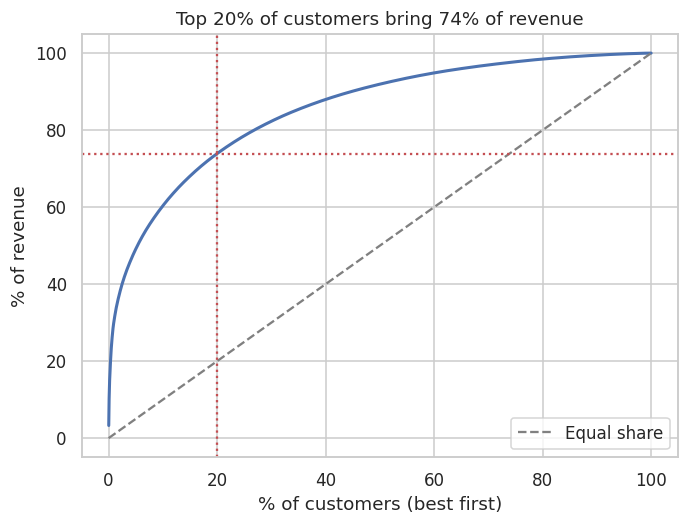

In [32]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(r["cum_customers_pct"], r["cum_revenue_pct"], color="#4C72B0", lw=2)
ax.plot([0, 100], [0, 100], "--", color="grey", label="Equal share")
ax.axvline(20, color="#C44E52", ls=":")
ax.axhline(top20_share, color="#C44E52", ls=":")
ax.set_title(f"Top 20% of customers bring {top20_share:.0f}% of revenue")
ax.set_xlabel("% of customers (best first)")
ax.set_ylabel("% of revenue")
ax.legend()
plt.savefig("charts/06_pareto_curve.png", bbox_inches="tight")
plt.show()

### Scatter plot 1: do customers who order more often also spend more?
Both axes use a log scale because a few customers are far bigger than the rest.

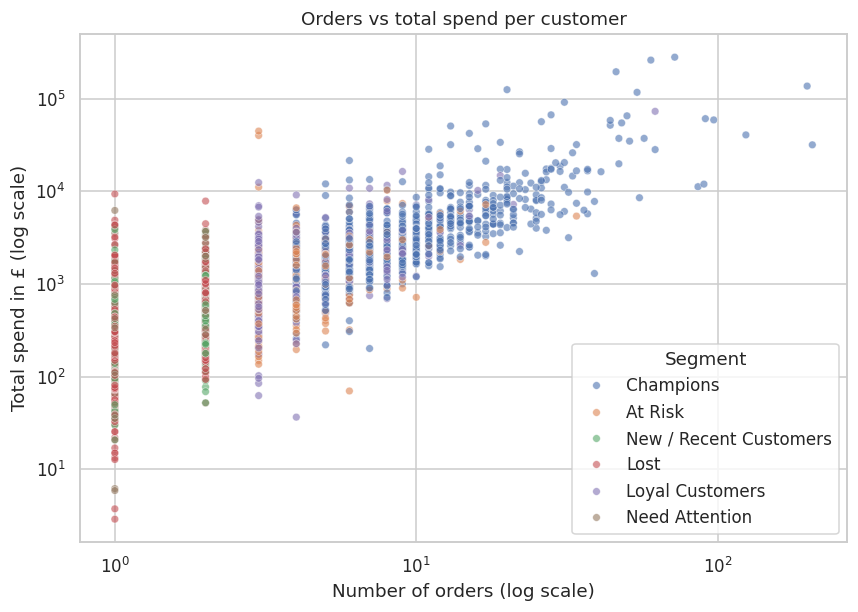

Spearman correlation between orders and spend: 0.81


In [33]:
fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=rfm, x="Frequency", y="Monetary", hue="Segment", alpha=0.6, s=25, ax=ax)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_title("Orders vs total spend per customer")
ax.set_xlabel("Number of orders (log scale)")
ax.set_ylabel("Total spend in £ (log scale)")
plt.savefig("charts/07_scatter_frequency_monetary.png", bbox_inches="tight")
plt.show()

rho_fm, _ = spearmanr(rfm["Frequency"], rfm["Monetary"])
print(f"Spearman correlation between orders and spend: {rho_fm:.2f}")

### Scatter plot 2: do cheap products sell more units?
Each dot is one product.

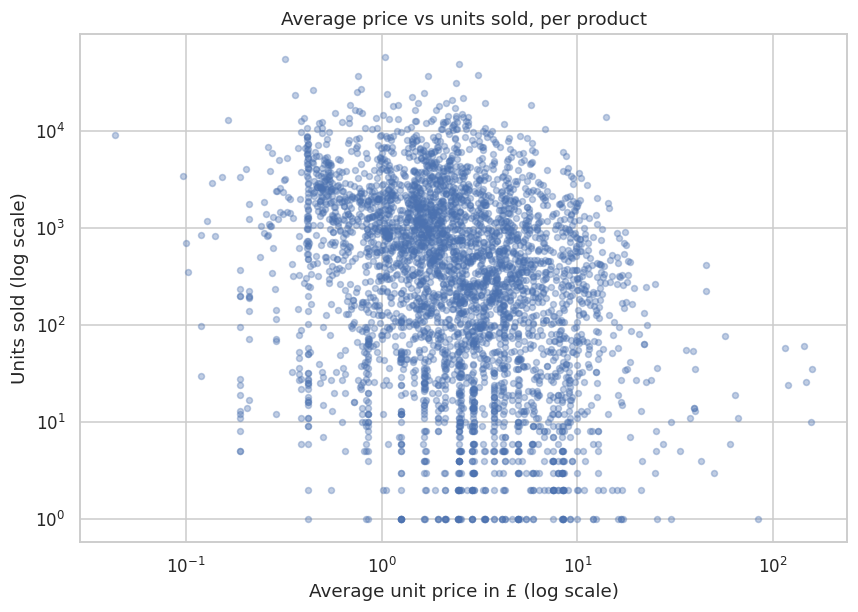

Spearman correlation between price and units sold: -0.33


In [34]:
prod = df.groupby("StockCode").agg(avg_price=("UnitPrice", "mean"), units=("Quantity", "sum"), revenue=("Revenue", "sum")).reset_index()
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(prod["avg_price"], prod["units"], alpha=0.35, s=15, color="#4C72B0")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_title("Average price vs units sold, per product")
ax.set_xlabel("Average unit price in £ (log scale)")
ax.set_ylabel("Units sold (log scale)")
plt.savefig("charts/08_scatter_price_units.png", bbox_inches="tight")
plt.show()

rho_pu, _ = spearmanr(prod["avg_price"], prod["units"])
print(f"Spearman correlation between price and units sold: {rho_pu:.2f}")

### Scatter plot 3: orders vs revenue by country (UK left out)

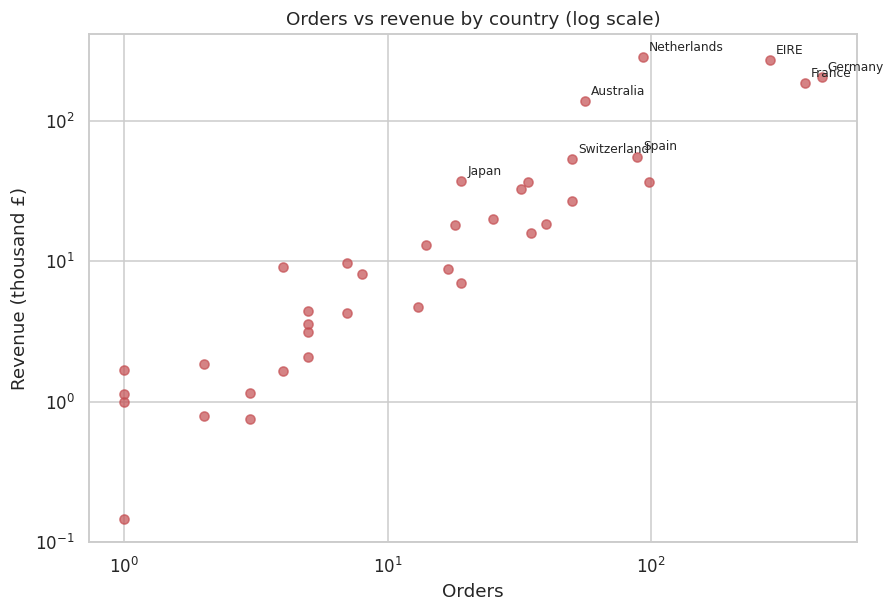

In [35]:
c2 = country[country["Country"] != "United Kingdom"]
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(c2["orders"], c2["revenue"] / 1000, color="#C44E52", alpha=0.7)
for _, row in c2.sort_values("revenue", ascending=False).head(8).iterrows():
    ax.annotate(row["Country"], (row["orders"], row["revenue"] / 1000), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_title("Orders vs revenue by country (log scale)")
ax.set_xlabel("Orders")
ax.set_ylabel("Revenue (thousand £)")
plt.savefig("charts/09_scatter_country.png", bbox_inches="tight")
plt.show()

### Interactive charts (Plotly)
These two are interactive: hover over them to see the numbers. GitHub does not show interactive Plotly output inside notebooks, so I also save them as HTML files in the `charts` folder.

In [36]:
fig = px.line(monthly, x="Month", y="Revenue", markers=True, title="Monthly revenue (December 2011 is a partial month)")
fig.update_layout(yaxis_title="Revenue (£)", xaxis_title="")
fig.write_html("charts/interactive_monthly_revenue.html", include_plotlyjs="cdn")
fig.show()

In [37]:
fig = px.treemap(seg, path=["Segment"], values="revenue", title="Revenue by customer segment",
                 hover_data={"customers": True, "pct_of_revenue": ":.1f"})
fig.write_html("charts/interactive_segments_treemap.html", include_plotlyjs="cdn")
fig.show()

In [38]:
# Collect the main numbers (used for the README and the findings below)
full_months = monthly[monthly["Month"] != "2011-12"]
best = full_months.loc[full_months["Revenue"].idxmax()]
worst = full_months.loc[full_months["Revenue"].idxmin()]
q4 = monthly[monthly["Month"].isin(["2011-09", "2011-10", "2011-11"])]["Revenue"].sum()
twelve_m = full_months[full_months["Month"] >= "2010-12"]["Revenue"].sum()

orders = df.groupby("InvoiceNo")["Revenue"].sum()
tp = top_products.iloc[::-1]
cnt = rfm["Frequency"]
champ = seg[seg["Segment"] == "Champions"].iloc[0]
atrisk = seg[seg["Segment"] == "At Risk"].iloc[0]
lost = seg[seg["Segment"] == "Lost"].iloc[0]
hour_orders = df.groupby("Hour")["InvoiceNo"].nunique().sort_values(ascending=False)
wk = df.groupby("Weekday")["InvoiceNo"].nunique().sort_values(ascending=False)
ret_value = -returns["Revenue"].sum()
dec_days = df[df["Month"] == "2011-12"]["InvoiceDate"].dt.date.nunique()
nov_days = df[df["Month"] == "2011-11"]["InvoiceDate"].dt.date.nunique()

K = {
    "raw_rows": int(len(raw)),
    "duplicates_removed": int(log[0]["rows_removed"]),
    "cancel_rows_moved": int(log[1]["rows_removed"]),
    "nonproduct_removed": int(log[2]["rows_removed"]),
    "bad_qty_price_removed": int(log[3]["rows_removed"]),
    "huge_orders_removed": int(log[4]["rows_removed"]),
    "clean_rows": int(len(df)),
    "pct_rows_kept": float(len(df) / len(raw) * 100),
    "total_revenue": float(df["Revenue"].sum()),
    "invoices": int(df["InvoiceNo"].nunique()),
    "avg_order_value": float(orders.mean()),
    "products": int(df["StockCode"].nunique()),
    "countries": int(df["Country"].nunique()),
    "known_customers": int(rfm.shape[0]),
    "missing_cust_rows_pct": float(df["CustomerID"].isna().mean() * 100),
    "missing_cust_revenue_pct": float(df.loc[df["CustomerID"].isna(), "Revenue"].sum() / df["Revenue"].sum() * 100),
    "uk_share_pct": float(uk_share * 100),
    "best_month": str(best["Month"]), "best_month_revenue": float(best["Revenue"]),
    "worst_month": str(worst["Month"]), "worst_month_revenue": float(worst["Revenue"]),
    "sep_nov_share_pct": float(q4 / twelve_m * 100) if twelve_m else None,
    "sep_nov_revenue": float(q4),
    "dec_days": int(dec_days), "nov_days": int(nov_days),
    "dec_rev_per_day": float(per_day["2011-12"]), "nov_rev_per_day": float(per_day["2011-11"]),
    "top_product": str(tp.iloc[0]["product"]), "top_product_revenue": float(tp.iloc[0]["revenue"]),
    "top10_products_share_pct": float(tp["revenue"].sum() / df["Revenue"].sum() * 100),
    "top_nonuk_country": str(other.iloc[-1]["Country"]), "top_nonuk_revenue": float(other.iloc[-1]["revenue"]),
    "top20_customer_share_pct": float(top20_share),
    "cust_for_80_pct": float(cust_for_80),
    "one_order_customers_pct": float((cnt == 1).mean() * 100),
    "repeat_customers_pct": float((cnt > 1).mean() * 100),
    "champions_customers_pct": float(champ["pct_of_customers"]),
    "champions_revenue_pct": float(champ["pct_of_revenue"]),
    "champions_customers": int(champ["customers"]),
    "atrisk_customers": int(atrisk["customers"]), "atrisk_revenue_pct": float(atrisk["pct_of_revenue"]),
    "lost_customers": int(lost["customers"]), "lost_revenue_pct": float(lost["pct_of_revenue"]),
    "return_value": float(ret_value),
    "return_pct_of_sales": float(ret_value / df["Revenue"].sum() * 100),
    "return_invoices": int(returns["InvoiceNo"].nunique()),
    "return_invoices_pct": float(returns["InvoiceNo"].nunique() / (returns["InvoiceNo"].nunique() + df["InvoiceNo"].nunique()) * 100),
    "busiest_hour": int(hour_orders.index[0]),
    "top_hours": [int(h) for h in hour_orders.index[:3]],
    "busiest_weekday": str(wk.index[0]),
    "weekdays_present": sorted(df["Weekday"].unique().tolist()),
    "rho_price_units": float(rho_pu),
    "rho_freq_monetary": float(rho_fm),
    "segments": seg[["Segment", "customers", "revenue", "pct_of_customers", "pct_of_revenue"]].round(2).to_dict("records"),
}
json.dump(K, open("outputs/key_numbers.json", "w"), indent=2)
print(json.dumps({k: v for k, v in K.items() if k != "segments"}, indent=1)[:2500])

{
 "raw_rows": 541909,
 "duplicates_removed": 5268,
 "cancel_rows_moved": 9251,
 "nonproduct_removed": 2406,
 "bad_qty_price_removed": 2480,
 "huge_orders_removed": 2,
 "clean_rows": 522502,
 "pct_rows_kept": 96.41877141734129,
 "total_revenue": 10001167.67,
 "invoices": 19771,
 "avg_order_value": 505.8503702392394,
 "products": 3899,
 "countries": 38,
 "known_customers": 4333,
 "missing_cust_rows_pct": 25.1394253036352,
 "missing_cust_revenue_pct": 15.094169799075072,
 "uk_share_pct": 84.77402139184413,
 "best_month": "2011-11",
 "best_month_revenue": 1452112.69,
 "worst_month": "2011-02",
 "worst_month_revenue": 507783.42,
 "sep_nov_share_pct": 37.50582235779617,
 "sep_nov_revenue": 3583737.4499999997,
 "dec_days": 8,
 "nov_days": 26,
 "dec_rev_per_day": 55752.25375,
 "nov_rev_per_day": 55850.48807692307,
 "top_product": "REGENCY CAKESTAND 3 TIER",
 "top_product_revenue": 174156.54,
 "top10_products_share_pct": 8.196414629252986,
 "top_nonuk_country": "Netherlands",
 "top_nonuk_reven

## 7. Findings

**Sales and timing**
- After cleaning, there are 522,502 sale lines and 19,771 orders, worth about £10.00 million. The average order is about £506.
- Sales grow strongly in the second half of 2011. September to November 2011 alone bring about £3.58 million, which is 38% of all revenue in the 12 full months (Dec 2010 to Nov 2011). November 2011 is the best month (£1.45 million). The weakest full month is 2011-02 (£508k).
- December 2011 looks like a crash, but the data stops on 9 December. Per trading day, December 2011 made about £55,752 against £55,850 in November, so it is not a real drop.
- Orders peak between 12:00 and 15:00. Thursday has the most orders. There are no orders on Saturdays in this data.

**Products and countries**
- The best product by revenue is "REGENCY CAKESTAND 3 TIER" (£174,157). The top 10 products together are only 8.2% of revenue, so sales are spread over many products (3,899 in total).
- The UK makes 85% of revenue. Outside the UK, Netherlands is the biggest market (£283,889).
- Cheap items sell more units: the correlation between price and units sold is -0.33 (negative means higher price, fewer units).

**Customers**
- 35% of known customers placed only one order, and 65% came back at least once.
- The top 20% of customers bring 74% of the revenue from known customers. 27% of customers are enough to make 80% of it.
- RFM segments:
  - Champions: 23.6% of customers, 66.8% of revenue
  - Loyal Customers: 13.6% of customers, 12.8% of revenue
  - At Risk: 8.9% of customers, 7.5% of revenue
  - Lost: 30.9% of customers, 7.1% of revenue
  - New / Recent Customers: 11.9% of customers, 3.0% of revenue
  - Need Attention: 11.0% of customers, 2.9% of revenue
- Champions are 1,023 customers (24% of the customers with an ID) and give 67% of the revenue from those customers (57% of the total £10.0M). The At Risk group (384 customers) used to buy often but has gone quiet, so they are the first group to contact with an offer.

**Returns**
- Cancellations and returns are worth about £230,248, which is 2.3% of sales value. About 14.7% of all invoices are cancellations.

**Data caveats**
- 25% of sale lines have no `CustomerID` (15% of revenue). They are used for sales analysis but not for customer analysis, so the customer numbers cover only the known customers.
- The data covers one year only, so I cannot tell if the Q4 rise is a yearly pattern or growth. A second year would be needed to say this.
- This is a shop that sells mostly to businesses (large quantities per order), so the results may not apply to a normal consumer shop.

## 8. Save the cleaned files

- `outputs/online_retail_cleaned.csv` is the full clean data (this is the file I use in Power BI).
- `outputs/rfm_customers.csv` has one row per customer with the RFM scores and segment.
- `outputs/online_retail_sample.csv` is a small random sample (5,000 rows) so the repo stays small.

In [39]:
export_cols = ["InvoiceNo", "StockCode", "Description", "Quantity", "InvoiceDate", "UnitPrice",
               "CustomerID", "Country", "Revenue", "Month", "Weekday", "Hour"]
df[export_cols].to_csv("outputs/online_retail_cleaned.csv", index=False)
df[export_cols].sample(5000, random_state=42).sort_values("InvoiceDate").to_csv("outputs/online_retail_sample.csv", index=False)
rfm.to_csv("outputs/rfm_customers.csv", index=False)
seg.to_csv("outputs/segment_summary.csv", index=False)
pd.DataFrame(log).to_csv("outputs/cleaning_log.csv", index=False)
print("Saved:", os.listdir("outputs"))

Saved: ['online_retail_sample.csv', 'cleaning_log.csv', 'key_numbers.json', 'segment_summary.csv', 'online_retail_cleaned.csv', 'rfm_customers.csv']
